
# DataVine Analytics: Summative Machine Learning Lab

## 1. Introduction

This project applies machine learning techniques to address three analytical problems presented by DataVine Analytics.

The project covers three tasks:

1. **Wine Classification:** Classifying wine categories using chemical properties, Principal Component Analysis (PCA), k-Nearest Neighbors (k-NN), and hyperparameter tuning.

2. **Agricultural Feed Recommendation:** Identifying similar chicken feed types using PCA and cosine similarity based on observed chicken weights.

3. **Regional Crime Pattern Analysis:** Identifying patterns in US state crime statistics using PCA, K-Means clustering, and Gaussian Mixture Models (GMM).

The analysis follows the assignment requirements, covering data preparation, model development, evaluation, visualization, and interpretation.



## 2. Library Imports

The following libraries are used for data manipulation, preprocessing, dimensionality reduction, classification, recommendation, clustering, model evaluation, and visualization.


In [1]:

import os

# Limit OpenMP threads to avoid Windows MKL warnings
os.environ["OMP_NUM_THREADS"] = "1"


In [2]:

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing and dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Recommendation system
from sklearn.metrics.pairwise import cosine_similarity

# Clustering
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture



## 3. Data Understanding and Preparation

This section examines the three datasets used in the DataVine Analytics project:

- **Wine Dataset:** Contains chemical measurements used to classify wines into different categories.
- **Chickwts Dataset:** Contains chicken weights and feed types used to identify feeds with similar performance outcomes.
- **USArrests Dataset:** Contains crime statistics for US states, used to identify regional crime patterns.

The datasets will be inspected for their dimensions, data types, missing values, duplicates, and inconsistencies. Numerical features will then be standardized before applying the required machine learning techniques.


In [3]:

# Load the three datasets
wine = pd.read_csv("wine.csv")
chickwts = pd.read_csv("chickwts.csv")
usarrests = pd.read_csv("USArrests.csv")

print("All three datasets loaded successfully.")


All three datasets loaded successfully.


In [4]:

# Check the number of rows and columns
print("Wine Dataset:", wine.shape)
print("Chickwts Dataset:", chickwts.shape)
print("USArrests Dataset:", usarrests.shape)


Wine Dataset: (178, 14)
Chickwts Dataset: (71, 2)
USArrests Dataset: (50, 5)


In [5]:

# Display the first five rows of each dataset
print("Wine Dataset")
display(wine.head())

print("Chickwts Dataset")
display(chickwts.head())

print("USArrests Dataset")
display(usarrests.head())


Wine Dataset


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Chickwts Dataset


,weight,feed
0,179,horsebean
1,160,horsebean
2,136,horsebean
3,227,horsebean
4,217,horsebean


USArrests Dataset


,rownames,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [6]:

# Inspect the structure and data types of each dataset

print("Wine Dataset Information")
wine.info()

print("\nChickwts Dataset Information")
chickwts.info()

print("\nUSArrests Dataset Information")
usarrests.info()


Wine Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-n

In [7]:

# Check missing values in each dataset

print("Wine Dataset Missing Values")
print(wine.isnull().sum())

print("\nChickwts Dataset Missing Values")
print(chickwts.isnull().sum())

print("\nUSArrests Dataset Missing Values")
print(usarrests.isnull().sum())


Wine Dataset Missing Values
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

Chickwts Dataset Missing Values
weight    0
feed      0
dtype: int64

USArrests Dataset Missing Values
rownames    0
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64


In [8]:

# Check for duplicate records in each dataset

print("Wine Dataset Duplicates:", wine.duplicated().sum())
print("Chickwts Dataset Duplicates:", chickwts.duplicated().sum())
print("USArrests Dataset Duplicates:", usarrests.duplicated().sum())


Wine Dataset Duplicates: 0
Chickwts Dataset Duplicates: 1
USArrests Dataset Duplicates: 0



### 3.1 Initial Data Quality Findings

The initial inspection of the three datasets revealed the following:

- **Wine Dataset:** Contains 178 observations and 14 columns, including 13 numerical predictors and one numerical target variable. No missing values or duplicate records were identified. The target variable is already numerically encoded.

- **Chickwts Dataset:** Contains 71 observations and two columns: weight and feed. No missing values were identified, but one duplicate record was detected. Since different chickens may have identical weights under the same feed type, the duplicate will be examined before deciding whether to remove it.

- **USArrests Dataset:** Contains 50 observations and five columns, including four numerical variables and one state identifier. No missing values or duplicate records were identified. The state identifier will be excluded from numerical modeling.

Overall, the datasets are complete, with no missing values requiring treatment. Further examination will focus on the duplicate observation, descriptive statistics, and potential data inconsistencies before standardization.


In [9]:

# Display repeated records in the Chickwts dataset
chickwts[chickwts.duplicated(keep=False)]


,weight,feed
24,248,soybean
35,248,soybean


In [10]:

# Generate descriptive statistics for all three datasets

print("Wine Dataset - Descriptive Statistics")
display(wine.describe())

print("Chickwts Dataset - Descriptive Statistics")
display(chickwts.describe(include="all"))

print("USArrests Dataset - Descriptive Statistics")
display(usarrests.describe(include="all"))


Wine Dataset - Descriptive Statistics


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Chickwts Dataset - Descriptive Statistics


,weight,feed
count,71.000000,71
unique,NaN,6
top,NaN,soybean
freq,NaN,14
mean,261.309859,NaN
std,78.073700,NaN
min,108.000000,NaN
25%,204.500000,NaN
50%,258.000000,NaN
75%,323.500000,NaN


USArrests Dataset - Descriptive Statistics


,rownames,Murder,Assault,UrbanPop,Rape
count,50,50.00000,50.000000,50.000000,50.000000
unique,50,NaN,NaN,NaN,NaN
top,Alabama,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN
mean,NaN,7.78800,170.760000,65.540000,21.232000
std,NaN,4.35551,83.337661,14.474763,9.366385
min,NaN,0.80000,45.000000,32.000000,7.300000
25%,NaN,4.07500,109.000000,54.500000,15.075000
50%,NaN,7.25000,159.000000,66.000000,20.100000
75%,NaN,11.25000,249.000000,77.750000,26.175000



### 3.2 Interpretation of Descriptive Statistics

**Wine Dataset**

- The dataset contains 178 observations across 13 chemical measurements and one target variable.
- The chemical measurements have different numerical ranges. For example, alcohol ranges from 11.03 to 14.83, while proline ranges from 278 to 1,680.
- The target variable contains three classes (0, 1, and 2), which will be used for wine classification.
- The differences in measurement scales confirm the need for standardization before applying PCA and k-NN.

**Chickwts Dataset**

- The dataset contains 71 observations across six feed categories.
- Chicken weights range from 108 to 423, with a mean of 261.31 and a standard deviation of 78.07.
- Soybean is the most frequently represented feed category, with 14 observations.
- Two records have identical values: a weight of 248 and a feed type of soybean. These records will be retained because they may represent different chickens with the same recorded weight.
- The weight variable will be standardized before applying PCA and cosine similarity.

**USArrests Dataset**

- The dataset contains crime statistics for 50 US states.
- The average values are 7.79 for Murder, 170.76 for Assault, 65.54 for UrbanPop, and 21.23 for Rape.
- The variables have different numerical ranges, particularly Assault, which ranges from 45 to 337.
- Each state has a unique identifier, and no duplicate records were identified.
- Standardization will be necessary before feature selection, PCA, and clustering.

**Overall Findings**

All three datasets contain complete observations, with no missing values. No confirmed data entry errors have been identified from the initial checks.

The datasets will be retained without removing observations. Numerical features will be standardized to ensure that differences in measurement scales do not distort the machine learning results.



### 3.3 Data Standardization

Standardization ensures that numerical features are measured on a comparable scale, with a mean of 0 and a standard deviation of 1.

This is necessary because the datasets contain variables with different numerical ranges, which could influence distance-based algorithms and Principal Component Analysis (PCA).

The following approach will be applied:

- **Wine Dataset:** Numerical predictors will be standardized within a machine learning pipeline after splitting the data into training and testing sets. This prevents data leakage.
- **Chickwts Dataset:** Chicken weights will be standardized before applying PCA and calculating cosine similarity.
- **USArrests Dataset:** Numerical features will be standardized before PCA and clustering.

The target variable in the Wine dataset and the categorical identifiers in the other datasets will not be standardized.



## 4. Wine Classification Using k-NN and PCA

### 4.1 Objective

The objective is to develop a classification model that predicts wine categories based on their chemical properties.

The analysis will use Principal Component Analysis (PCA) to reduce dimensionality while retaining 95% of the variance. A k-Nearest Neighbors (k-NN) classifier will then be trained, with GridSearchCV used to identify the optimal number of neighbors and distance metric.

The model will be evaluated using classification accuracy and a classification report containing precision, recall, and F1-scores.



### 4.2 Feature and Target Selection

The Wine dataset contains 13 numerical predictor variables representing chemical measurements and one target variable representing the wine category.

The target variable is already encoded into three numerical classes (0, 1, and 2), so further label encoding is not required.

The predictors and target will be separated before splitting the data into training and testing sets.


In [11]:

# Separate predictor variables and target
X_wine = wine.drop(columns=["target"])
y_wine = wine["target"]

# Confirm the dimensions
print("Predictor variables:", X_wine.shape)
print("Target variable:", y_wine.shape)

# Check target classes
print("\nTarget class distribution:")
print(y_wine.value_counts().sort_index())


Predictor variables: (178, 13)
Target variable: (178,)

Target class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64



### 4.3 Train-Test Split

The Wine dataset will be divided into training and testing sets using an 80:20 ratio.

The training set will be used for model development and hyperparameter tuning, while the testing set will provide an independent evaluation of model performance.

Stratified sampling will preserve the proportion of each wine category in both sets. A random state of 42 will ensure reproducibility.

Standardization and PCA will be fitted using training data only to prevent data leakage.


In [12]:

# Split the Wine dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    random_state=42,
    stratify=y_wine
)

# Display the resulting dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (142, 13)
Testing features: (36, 13)
Training target: (142,)
Testing target: (36,)



### 4.4 Interpretation of Data Splitting

The Wine dataset contains 178 observations and 13 predictor variables. The target variable has three classes:

- Class 0: 59 observations
- Class 1: 71 observations
- Class 2: 48 observations

The dataset was divided into 142 training observations (80%) and 36 testing observations (20%).

Stratified sampling was used to preserve the class proportions across the training and testing sets.

The training data will be used for model development and hyperparameter tuning, while the testing data will be reserved for final model evaluation.



### 4.5 Standardization and PCA

The Wine dataset contains chemical measurements with different numerical scales. StandardScaler will be used to standardize the predictor variables.

Principal Component Analysis (PCA) will then reduce the number of features while retaining 95% of the total variance.

A machine learning pipeline will combine standardization, PCA, and k-NN classification. This ensures that preprocessing is performed correctly within each cross-validation fold, preventing data leakage.


In [13]:

# Create a pipeline for standardization, PCA, and k-NN
wine_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("knn", KNeighborsClassifier())
])

print("Wine classification pipeline created successfully.")


Wine classification pipeline created successfully.



### 4.6 Hyperparameter Tuning Using GridSearchCV

GridSearchCV will be used to identify the best combination of hyperparameters for the k-NN classifier.

Two hyperparameters will be evaluated:

- **Number of neighbors (k):** Determines how many nearby observations are considered when making predictions.
- **Distance metric:** Determines how distances between observations are calculated.

Five-fold stratified cross-validation will be used to evaluate the parameter combinations. Classification accuracy will be the scoring metric.


In [14]:

# Define hyperparameters for k-NN
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "knn__metric": ["euclidean", "manhattan"]
}

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=wine_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("GridSearchCV configured successfully.")


GridSearchCV configured successfully.


In [15]:

# Fit GridSearchCV on the training data
grid_search.fit(X_train, y_train)

# Display the best hyperparameters and cross-validation accuracy
print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")


Best Parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 11}
Best Cross-Validation Accuracy: 0.9650



### 4.7 Interpretation of Hyperparameter Tuning

GridSearchCV identified the following optimal hyperparameters for the k-NN classifier:

- **Number of neighbors (k):** 11
- **Distance metric:** Euclidean
- **Best cross-validation accuracy:** 96.50%

The model achieved a mean cross-validation accuracy of 96.50%, indicating strong classification performance across the five folds.

The selected combination of k = 11 and Euclidean distance achieved the highest mean cross-validation accuracy among the tested parameter combinations.

These results suggest that the model can distinguish between wine categories based on their chemical properties.

### 4.8 Model Evaluation

The best-performing k-NN model will be evaluated using the independent testing dataset to assess its ability to classify unseen observations.

The evaluation will use:

- **Accuracy:** Measures the proportion of correctly classified observations.
- **Precision:** Measures the proportion of predictions for each category that are correct.
- **Recall:** Measures the proportion of actual observations in each category correctly identified.
- **F1-score:** Combines precision and recall into a single measure.

The test accuracy will be compared with the cross-validation accuracy to assess model consistency and identify any differences in performance across wine categories.


In [16]:

# Retrieve the best-performing k-NN model
best_knn_model = grid_search.best_estimator_

# Make predictions on the testing dataset
y_pred = best_knn_model.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")

# Generate the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36




### 4.9 Interpretation of Model Evaluation Results

The optimized k-NN classifier achieved a test accuracy of **100%**, correctly classifying all 36 observations in the testing dataset.

The classification report shows:

- **Class 0:** All 12 observations were correctly classified, with precision, recall, and F1-score of 1.00.
- **Class 1:** All 14 observations were correctly classified, with precision, recall, and F1-score of 1.00.
- **Class 2:** All 10 observations were correctly classified, with precision, recall, and F1-score of 1.00.

Both the macro-average and weighted-average F1-scores were 1.00, indicating consistent classification performance across all three wine categories.

The test accuracy of 100% exceeded the cross-validation accuracy of 96.50%. This suggests that the model performed well on the independent testing dataset.

The results demonstrate that combining standardization, PCA, and a tuned k-NN classifier can effectively distinguish wine categories based on their chemical properties.

Although the model achieved perfect accuracy on the testing dataset, the results are based on only 36 observations. Performance on larger or different datasets may vary.


In [17]:

# Retrieve the fitted PCA model from the best pipeline
fitted_pca = best_knn_model.named_steps["pca"]

# Display the number of retained components
print("Number of Principal Components:", fitted_pca.n_components_)

# Display the total explained variance
print(
    f"Total Explained Variance: "
    f"{fitted_pca.explained_variance_ratio_.sum():.2%}"
)


Number of Principal Components: 10
Total Explained Variance: 96.24%



### 4.10 Interpretation of PCA Results

Principal Component Analysis (PCA) reduced the original 13 chemical features to 10 principal components while retaining **96.24% of the total variance**.

This exceeds the assignment's minimum requirement of retaining 95% of the variance.

The reduction eliminated three dimensions, representing approximately 23.1% of the original feature space, while preserving most of the information contained in the standardized chemical measurements.

The PCA results, combined with the model's cross-validation accuracy of 96.50% and test accuracy of 100%, indicate that the reduced feature space supported strong wine classification performance.

Overall, the classification model successfully met the project objective of distinguishing wine categories using their chemical properties.



## 5. Agricultural Feed Recommendation System

### 5.1 Objective

The objective is to develop a recommendation system that identifies feed types associated with similar chicken weight outcomes.

The Chickwts dataset contains chicken weights recorded under six different feed categories.

The analysis will involve standardizing chicken weights, applying Principal Component Analysis (PCA) to obtain one principal component, and calculating cosine similarity between feed types.

The resulting similarity scores will be used to identify comparable feed categories and generate recommendations based on observed chicken weight outcomes.


### 5.2 Standardization and Principal Component Analysis

The Chickwts dataset contains chicken weights and their corresponding feed categories.

The weight variable will be standardized using StandardScaler to produce values with a mean of approximately zero and a standard deviation of one.

Principal Component Analysis (PCA) will then be applied to obtain one principal component, as required by the assignment.

Since weight is the only numerical feature, PCA will retain all the variance rather than reduce the number of dimensions. The resulting component will be used to represent chicken weight outcomes for the feed recommendation analysis.


In [18]:

# Select the numerical feature
X_chickwts = chickwts[["weight"]]

# Standardize chicken weights
chickwts_scaler = StandardScaler()
chickwts_scaled = chickwts_scaler.fit_transform(X_chickwts)

# Display the first five standardized values
print("Standardized Chicken Weights:")
print(chickwts_scaled[:5])

# Verify standardization
print(f"\nMean: {chickwts_scaled.mean():.4f}")
print(f"Standard Deviation: {chickwts_scaled.std():.4f}")


Standardized Chicken Weights:
[[-1.06176218]
 [-1.3068541 ]
 [-1.61644389]
 [-0.44258259]
 [-0.57157834]]

Mean: -0.0000
Standard Deviation: 1.0000


In [19]:

# Apply PCA to obtain one principal component
chickwts_pca = PCA(n_components=1)

chickwts_pca_values = chickwts_pca.fit_transform(chickwts_scaled)

# Display PCA results
print("PCA Output Shape:", chickwts_pca_values.shape)

print(
    "Explained Variance Ratio:",
    chickwts_pca.explained_variance_ratio_
)

print("\nFirst Five PCA Values:")
print(chickwts_pca_values[:5])


PCA Output Shape: (71, 1)
Explained Variance Ratio: [1.]

First Five PCA Values:
[[-1.06176218]
 [-1.3068541 ]
 [-1.61644389]
 [-0.44258259]
 [-0.57157834]]




### 5.3 Interpretation of Standardization and PCA Results

The chicken weight variable was successfully standardized, producing a mean of approximately 0 and a standard deviation of 1.

PCA was applied to obtain one principal component, producing 71 observations and one component.

The principal component explained **100% of the variance**, as chicken weight is the only numerical feature in the dataset.

The PCA values are identical to the standardized weights, confirming that no dimensionality reduction occurred.

Although the PCA requirement has been satisfied, the single-component representation provides limited information for comparing feed types.

### 5.4 Cosine Similarity Between Feed Types

Cosine similarity measures the similarity between two vectors based on their direction.

To compare feed types, the principal component scores will be aggregated by feed category using their mean values. This produces one representative score for each of the six feed types.

Cosine similarity will then be calculated between these feed-level representations.

Since each feed is represented by a single component, cosine similarity will primarily indicate whether feed categories have scores in the same direction rather than how close their average chicken weights are.

This limitation will be considered when interpreting the recommendations.


In [20]:

# Create a DataFrame containing feed types and PCA scores
feed_pca_df = pd.DataFrame({
    "feed": chickwts["feed"],
    "PC1": chickwts_pca_values.flatten()
})

# Calculate the mean PCA score for each feed type
feed_profiles = feed_pca_df.groupby("feed")[["PC1"]].mean()

print("Mean PCA Scores by Feed Type:")
display(feed_profiles)


Mean PCA Scores by Feed Type:


,PC1
feed,
casein,0.803301
horsebean,-1.304274
linseed,-0.549004
meatmeal,0.201223
soybean,-0.191962
sunflower,0.872099


In [21]:

# Calculate cosine similarity between feed types
feed_similarity = cosine_similarity(feed_profiles)

# Convert the similarity scores into a DataFrame
feed_similarity_df = pd.DataFrame(
    feed_similarity,
    index=feed_profiles.index,
    columns=feed_profiles.index
)

print("Cosine Similarity Matrix:")
display(feed_similarity_df.round(4))


Cosine Similarity Matrix:


feed,casein,horsebean,linseed,meatmeal,soybean,sunflower
feed,,,,,,
casein,1.0,-1.0,-1.0,1.0,-1.0,1.0
horsebean,-1.0,1.0,1.0,-1.0,1.0,-1.0
linseed,-1.0,1.0,1.0,-1.0,1.0,-1.0
meatmeal,1.0,-1.0,-1.0,1.0,-1.0,1.0
soybean,-1.0,1.0,1.0,-1.0,1.0,-1.0
sunflower,1.0,-1.0,-1.0,1.0,-1.0,1.0



### 5.5 Interpretation of Cosine Similarity Results

The mean PCA scores divided the six feed categories into two groups:

- **Positive scores:** Casein (0.8033), meatmeal (0.2012), and sunflower (0.8721).
- **Negative scores:** Horsebean (-1.3043), linseed (-0.5490), and soybean (-0.1920).

Positive scores indicate average chicken weights above the overall mean, while negative scores indicate averages below the overall mean.

The cosine similarity matrix produced two values:

- **+1.0:** Feed types with PCA scores in the same direction.
- **-1.0:** Feed types with PCA scores in opposite directions.

For example, casein and sunflower have a similarity score of 1.0, while casein and horsebean have a score of -1.0.

**Limitation:** Because each feed is represented by only one principal component, cosine similarity cannot measure how close their average chicken weights are. Feed types with substantially different mean weights can receive identical similarity scores.

The results therefore provide broad groupings rather than precise rankings of feed performance.


In [22]:

# Generate feed recommendations based on cosine similarity
feed_recommendations = {}

for feed in feed_similarity_df.index:
    similarities = feed_similarity_df.loc[feed].drop(feed)

    # Identify feeds with the highest similarity score
    max_similarity = similarities.max()
    recommended_feeds = similarities[
        np.isclose(similarities, max_similarity)
    ].index.tolist()

    feed_recommendations[feed] = {
        "Recommended Feeds": ", ".join(recommended_feeds),
        "Similarity Score": max_similarity
    }

# Display recommendations
recommendations_df = pd.DataFrame.from_dict(
    feed_recommendations,
    orient="index"
)

recommendations_df.index.name = "Feed Type"

display(recommendations_df)


,Recommended Feeds,Similarity Score
Feed Type,,
casein,"meatmeal, sunflower",1.0
horsebean,"linseed, soybean",1.0
linseed,"horsebean, soybean",1.0
meatmeal,"casein, sunflower",1.0
soybean,"horsebean, linseed",1.0
sunflower,"casein, meatmeal",1.0



### 5.6 Interpretation of Feed Recommendations

The recommendation system identified feed types with similar mean PCA score directions.

The recommendations are:

- **Casein:** Meatmeal and sunflower (similarity score: 1.0).
- **Horsebean:** Linseed and soybean (similarity score: 1.0).
- **Linseed:** Horsebean and soybean (similarity score: 1.0).
- **Meatmeal:** Casein and sunflower (similarity score: 1.0).
- **Soybean:** Horsebean and linseed (similarity score: 1.0).
- **Sunflower:** Casein and meatmeal (similarity score: 1.0).

The recommendations form two groups. Casein, meatmeal, and sunflower have average chicken weights above the overall mean, while horsebean, linseed, and soybean have averages below the overall mean.

### 5.7 Limitations of the Recommendation System

Although the system successfully applied PCA and cosine similarity, its recommendations have limitations.

Since the dataset contains only one numerical feature, PCA does not reduce dimensionality. Cosine similarity also produces identical scores for feed types whose mean PCA scores have the same sign, regardless of differences in their average chicken weights.

Therefore, a similarity score of 1.0 does not necessarily indicate that two feeds produce nearly identical weight outcomes.

The recommendations should be interpreted as broad performance groupings rather than precise measures of feed equivalence.

For more meaningful comparisons, differences in average chicken weights could be examined alongside cosine similarity. Further information, such as feed composition, cost, and nutritional value, would also be needed before making practical feed recommendations.


In [23]:

# Calculate average chicken weight for each feed type
feed_mean_weights = chickwts.groupby("feed")["weight"].mean()

# Display average weights in descending order
print("Average Chicken Weight by Feed Type:")
display(
    feed_mean_weights.sort_values(
        ascending=False
    ).round(2)
)


Average Chicken Weight by Feed Type:


feed
sunflower    328.92
casein       323.58
meatmeal     276.91
soybean      246.43
linseed      218.75
horsebean    160.20
Name: weight, dtype: float64


### 5.8 Interpretation of Average Chicken Weights

The comparison of average chicken weights provides further insight into feed performance.

Sunflower recorded the highest average weight (328.92), followed closely by casein (323.58). The difference between these feeds was only 5.34 weight units, indicating similar average outcomes.

Meatmeal recorded an average weight of 276.91, followed by soybean (246.43), linseed (218.75), and horsebean (160.20).

Although cosine similarity assigned a score of 1.0 to casein, sunflower, and meatmeal, the average weights show that sunflower and casein produced considerably closer outcomes than either did with meatmeal.

This demonstrates that comparing average weights provides a more meaningful basis for identifying feeds with similar observed performance.

### 5.9 Conclusion: Agricultural Feed Recommendation System

The analysis successfully standardized chicken weights, applied PCA with one principal component, calculated cosine similarity between six feed categories, and generated feed recommendations.

PCA explained 100% of the variance because the dataset contained only one numerical feature.

Cosine similarity identified two broad groups of feeds based on whether their average chicken weights were above or below the overall mean.

A supplementary comparison of average weights showed that sunflower and casein had the closest average outcomes among the six feeds.

The findings demonstrate that cosine similarity alone is insufficient for ranking feed performance when each feed is represented by a single numerical value.

The recommendation system therefore provides an initial comparison of feed categories, but more features would be required to develop a more informative recommendation model.



## 6. USArrests Clustering Analysis

### 6.1 Objective

The objective is to identify groups of US states with similar crime and demographic characteristics using unsupervised machine learning.

The analysis will use the USArrests dataset, which contains information on 50 US states and four variables:

- **Murder:** Murder arrests per 100,000 residents.
- **Assault:** Assault arrests per 100,000 residents.
- **UrbanPop:** Percentage of the population living in urban areas.
- **Rape:** Rape arrests per 100,000 residents.

The analysis will involve selecting three relevant features, standardizing the data, and applying PCA to obtain two principal components.

Two clustering methods will then be applied:

1. **K-Means Clustering:** The elbow method will be used to determine an appropriate number of clusters.
2. **Gaussian Mixture Model (GMM):** The Bayesian Information Criterion (BIC) will be used to select the number of clusters.

The resulting clusters will be visualized and compared to identify patterns in the data.

### 6.2 Feature Selection

The assignment requires selecting three relevant features from the four available numerical variables.

Feature selection will be informed by examining correlations between the variables and their relationships with the underlying crime patterns.

A correlation matrix will help identify variables that contain overlapping information and support the selection of three features for clustering.

The state names will be excluded from the numerical analysis because they serve as identifiers rather than predictors.


USArrests Feature Correlation Matrix:


,Murder,Assault,UrbanPop,Rape
Murder,1.000,0.802,0.070,0.564
Assault,0.802,1.000,0.259,0.665
UrbanPop,0.070,0.259,1.000,0.411
Rape,0.564,0.665,0.411,1.000


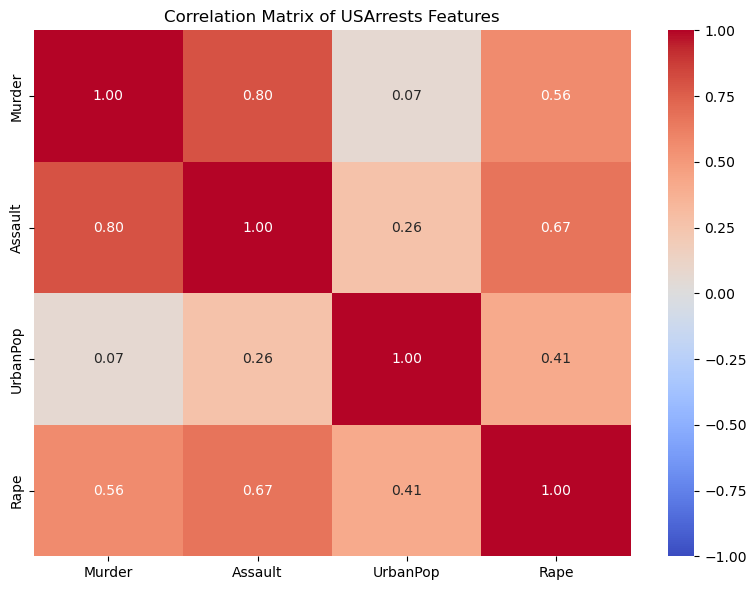

In [24]:

# Select the four numerical variables
usarrests_features = usarrests[
    ["Murder", "Assault", "UrbanPop", "Rape"]
]

# Calculate the correlation matrix
usarrests_corr = usarrests_features.corr()

print("USArrests Feature Correlation Matrix:")
display(usarrests_corr.round(3))

# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    usarrests_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of USArrests Features")
plt.tight_layout()
plt.show()



### 6.3 Interpretation of Feature Correlations

The correlation matrix revealed several relationships between the USArrests variables.

- **Murder and Assault (0.802):** A strong positive correlation, indicating that states with higher murder arrest rates also tend to have higher assault arrest rates.
- **Assault and Rape (0.665):** A moderately strong positive correlation, suggesting some overlap in the information captured by these variables.
- **Murder and Rape (0.564):** A moderate positive correlation.
- **UrbanPop and Murder (0.070):** A very weak correlation, suggesting that urban population percentage provides information largely distinct from murder arrest rates.
- **UrbanPop and Assault (0.259):** A weak positive correlation.
- **UrbanPop and Rape (0.411):** A moderate positive correlation.

### 6.4 Selection of the Three Most Relevant Features

Based on the correlation analysis and the objective of identifying states with similar crime and demographic characteristics, the following features were selected:

1. **Murder:** Represents the frequency of murder arrests.
2. **Assault:** Represents the frequency of assault arrests.
3. **UrbanPop:** Captures the proportion of residents living in urban areas.

Although Murder and Assault are strongly correlated, both were retained because they represent distinct crime measures.

UrbanPop was selected because it introduces a demographic dimension that is less strongly correlated with the selected crime variables.

Rape was excluded because it shows moderate correlations with Murder and Assault, suggesting some overlap in the information captured.

The selection balances crime-related measures with demographic information. It is a reasoned choice based on the available variables rather than a formal measure of feature importance.


In [25]:

# Select the three features for clustering
selected_features = ["Murder", "Assault", "UrbanPop"]

X_usarrests = usarrests[selected_features]

# Standardize the selected features
usarrests_scaler = StandardScaler()
X_usarrests_scaled = usarrests_scaler.fit_transform(X_usarrests)

# Verify standardization
print("Selected Features:", selected_features)
print("Standardized Data Shape:", X_usarrests_scaled.shape)

print("\nStandardized Feature Means:")
print(X_usarrests_scaled.mean(axis=0).round(4))

print("\nStandardized Feature Standard Deviations:")
print(X_usarrests_scaled.std(axis=0).round(4))


Selected Features: ['Murder', 'Assault', 'UrbanPop']
Standardized Data Shape: (50, 3)

Standardized Feature Means:
[-0.  0. -0.]

Standardized Feature Standard Deviations:
[1. 1. 1.]


In [26]:

# Apply PCA to obtain two principal components
usarrests_pca = PCA(n_components=2)

X_usarrests_pca = usarrests_pca.fit_transform(
    X_usarrests_scaled
)

print("PCA Output Shape:", X_usarrests_pca.shape)

print("\nExplained Variance Ratio:")
print(usarrests_pca.explained_variance_ratio_.round(4))

print(
    "\nTotal Explained Variance:",
    f"{usarrests_pca.explained_variance_ratio_.sum():.2%}"
)


PCA Output Shape: (50, 2)

Explained Variance Ratio:
[0.6217 0.3198]

Total Explained Variance: 94.15%




### 6.5 Interpretation of Standardization Results

The three selected features (Murder, Assault, and UrbanPop) were successfully standardized.

Each feature has a mean of approximately 0 and a standard deviation of 1, confirming that standardization was applied correctly.

Standardization ensures that variables measured on different scales contribute comparably to PCA and the subsequent clustering analysis.

### 6.6 Interpretation of PCA Results

PCA reduced the three standardized features to two principal components for all 50 states.

The explained variance ratios were:

- **Principal Component 1 (PC1):** 62.17%
- **Principal Component 2 (PC2):** 31.98%
- **Total explained variance:** 94.15%

The two components retain most of the variation in the selected features, with only 5.85% of the variance not represented.

This indicates that the two-dimensional PCA representation preserves most of the information needed to explore patterns among states.

The PCA-transformed data will be used for K-Means and Gaussian Mixture Model clustering, allowing both methods to be compared using the same two-dimensional representation.

### 6.7 K-Means Clustering and the Elbow Method

K-Means is an unsupervised learning algorithm that groups observations into clusters based on their similarity.

The algorithm assigns each observation to the nearest cluster centroid and seeks to minimize the within-cluster sum of squared distances, also known as inertia.

The elbow method helps determine an appropriate number of clusters by comparing inertia across different values of K.

As the number of clusters increases, inertia decreases. The preferred number of clusters is generally near the point where further increases in K produce smaller improvements.

The elbow method will be applied to the two principal components obtained from PCA.


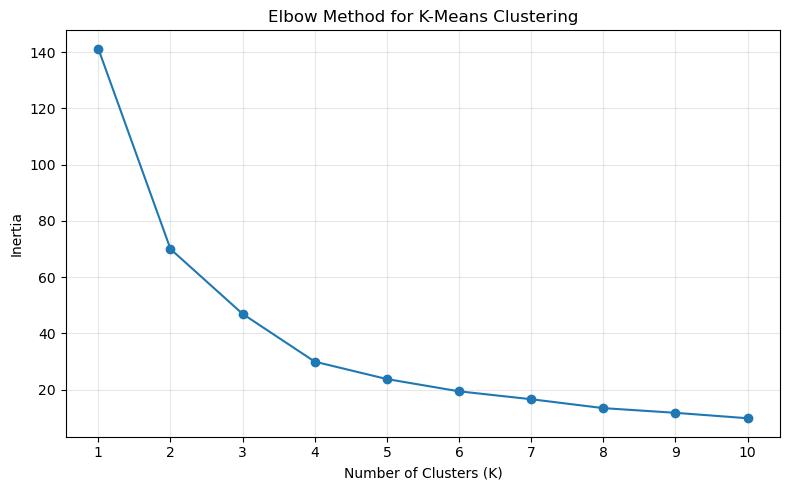

In [27]:

# Test different numbers of clusters
k_values = range(1, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_usarrests_pca)
    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Silhouette Scores by Number of Clusters:


,Clusters,Silhouette Score
0,2,0.4317
1,3,0.3919
2,4,0.4253
3,5,0.4016
4,6,0.4012
5,7,0.3849
6,8,0.3888
7,9,0.3882
8,10,0.4025


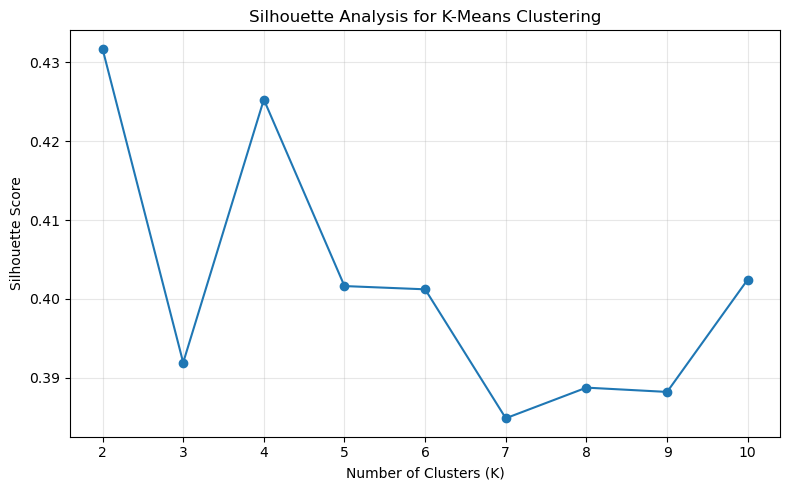

Best K based on Silhouette Score: 2


In [28]:

from sklearn.metrics import silhouette_score

# Calculate silhouette scores for different cluster numbers
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_usarrests_pca)

    score = silhouette_score(X_usarrests_pca, labels)
    silhouette_scores.append(score)

# Display the scores
silhouette_results = pd.DataFrame({
    "Clusters": range(2, 11),
    "Silhouette Score": silhouette_scores
})

print("Silhouette Scores by Number of Clusters:")
display(silhouette_results.round(4))

# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_results["Clusters"],
    silhouette_results["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means Clustering")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Best K based on Silhouette Score:",
    silhouette_results.loc[
        silhouette_results["Silhouette Score"].idxmax(),
        "Clusters"
    ]
)




### 6.8 Interpretation of the Elbow Method

The elbow method was applied to determine an appropriate number of clusters for K-Means.

The results show a substantial reduction in inertia as the number of clusters increases from 1 to 4.

Beyond four clusters, the rate of improvement becomes smaller, suggesting diminishing returns from increasing the number of clusters.

Based on the elbow plot, K = 4 was selected as a reasonable number of clusters.

Since the elbow was not sharply defined, silhouette analysis was conducted to provide additional evidence for selecting the number of clusters.

### 6.9 Silhouette Analysis and Final Cluster Selection

Silhouette scores were calculated for K values ranging from 2 to 10.

The highest silhouette score was **0.4317 at K = 2**, indicating the strongest average cluster separation among the tested solutions.

The four-cluster solution achieved a silhouette score of **0.4253**, only 0.0064 below the highest score.

Although K = 2 performed slightly better based on silhouette analysis, K = 4 was retained because it was supported by the elbow method and provided more detailed groupings of states.

The four-cluster solution also revealed interpretable differences in murder arrest rates, assault arrest rates, and urban population percentages.

Therefore, K = 4 was selected as a reasonable compromise between cluster separation and the level of detail provided by the resulting groups.

This choice does not establish four as the objectively optimal number of clusters, since the two evaluation methods produced different preferences.


In [29]:

# Fit K-Means using the selected number of clusters
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign each state to a cluster
kmeans_labels = kmeans_final.fit_predict(X_usarrests_pca)

# Create a DataFrame for visualization and analysis
usarrests_clusters = pd.DataFrame(
    X_usarrests_pca,
    columns=["PC1", "PC2"]
)

usarrests_clusters["KMeans_Cluster"] = kmeans_labels

# Display cluster sizes
print("K-Means Cluster Distribution:")
print(
    usarrests_clusters["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)


K-Means Cluster Distribution:
KMeans_Cluster
0    13
1    10
2    18
3     9
Name: count, dtype: int64


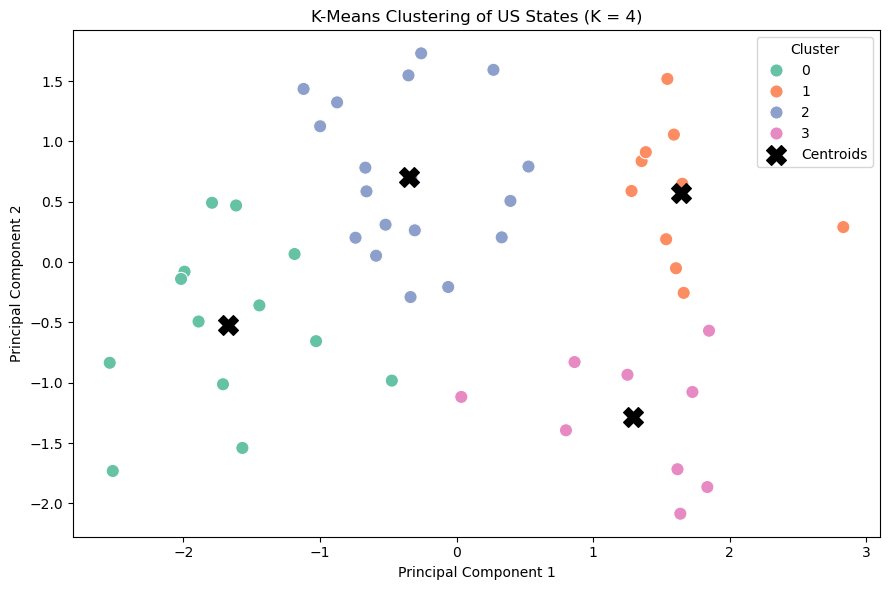

In [30]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=usarrests_clusters,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set2",
    s=90
)

# Plot cluster centroids
plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Centroids"
)

plt.title("K-Means Clustering of US States (K = 4)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()



### 6.10 Interpretation of K-Means Clustering Results

K-Means clustering was applied to the two principal components using four clusters, as selected through the elbow method.

The 50 US states were distributed as follows:

- **Cluster 0:** 13 states
- **Cluster 1:** 10 states
- **Cluster 2:** 18 states
- **Cluster 3:** 9 states

Cluster 2 contains the largest number of states, while Cluster 3 contains the fewest.

The scatter plot shows four reasonably distinct groups in the two-dimensional PCA space.

Clusters 0 and 2 are mainly positioned on the negative side of the first principal component, while Clusters 1 and 3 are mainly positioned on the positive side.

The second principal component provides further separation, particularly between Clusters 1 and 3.

The black markers represent cluster centroids, indicating the central position of each group.

These findings suggest that the selected crime and demographic variables contain patterns that allow states to be grouped into distinct categories.

The clusters have not yet been assigned descriptive labels because their underlying crime and demographic characteristics have not been examined.

### 6.11 Gaussian Mixture Model (GMM) Clustering

Gaussian Mixture Models provide an alternative approach to clustering by assuming that the data originates from a mixture of Gaussian distributions.

Unlike K-Means, which assigns observations to clusters based on their distance from centroids, GMM estimates the probability that each observation belongs to a particular cluster.

GMM can accommodate clusters with different shapes and spreads.

The Bayesian Information Criterion (BIC) will be used to determine an appropriate number of clusters.

BIC balances model fit against model complexity, with lower values indicating a preferred model.

The GMM analysis will use the same two principal components as K-Means to allow comparison between the clustering methods.


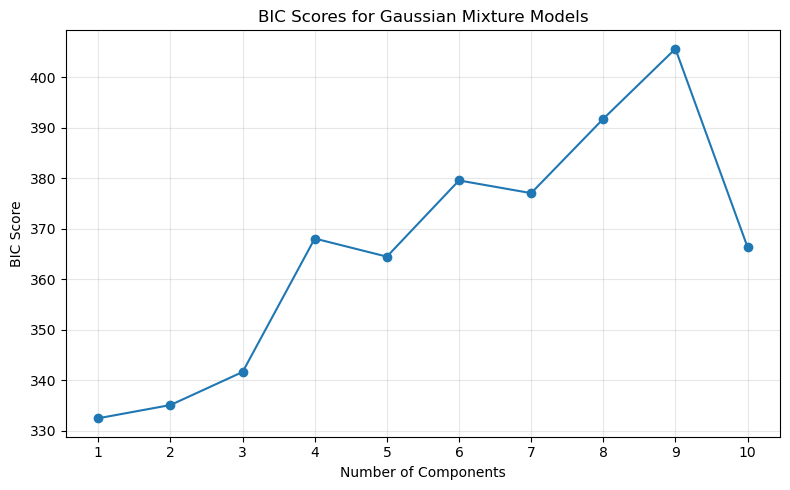

Optimal Number of GMM Clusters: 1
Lowest BIC Score: 332.44


In [31]:

# Test different numbers of GMM clusters
gmm_components = range(1, 11)
bic_scores = []

for n in gmm_components:
    gmm = GaussianMixture(
        n_components=n,
        covariance_type="full",
        random_state=42,
        n_init=10
    )

    gmm.fit(X_usarrests_pca)
    bic_scores.append(gmm.bic(X_usarrests_pca))

# Plot BIC scores
plt.figure(figsize=(8, 5))

plt.plot(
    list(gmm_components),
    bic_scores,
    marker="o"
)

plt.xlabel("Number of Components")
plt.ylabel("BIC Score")
plt.title("BIC Scores for Gaussian Mixture Models")
plt.xticks(list(gmm_components))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display the optimal number of components
optimal_gmm_clusters = list(gmm_components)[
    np.argmin(bic_scores)
]

print("Optimal Number of GMM Clusters:", optimal_gmm_clusters)
print("Lowest BIC Score:", round(min(bic_scores), 2))



### 6.12 Interpretation of GMM BIC Results

The Bayesian Information Criterion (BIC) was calculated for Gaussian Mixture Models containing between 1 and 10 components.

The lowest BIC score was **332.44**, corresponding to **one component**.

BIC generally increased as additional components were introduced, indicating that more complex models did not provide sufficient improvements in fit to justify the additional parameters.

Based on the BIC results, a single-component GMM was selected.

This differs from the K-Means analysis, where the elbow method suggested four clusters.

The difference reflects the distinct approaches used by the two methods. K-Means minimizes within-cluster distances, while GMM uses a probabilistic model and BIC penalizes unnecessary complexity.

The BIC result suggests that the data does not provide sufficient evidence to favour multiple Gaussian components under the tested model settings.

### 6.13 Fitting the Final Gaussian Mixture Model

The final GMM will be fitted using one component, as selected by BIC.

Since the model contains only one component, all 50 states will be assigned to the same group.

Although this does not produce distinct clusters, it is consistent with the model selection results and provides a useful comparison with K-Means.

The final GMM assignments will be visualized in the same PCA space used for K-Means.


In [32]:

# Fit the final GMM using the BIC-selected number of components
gmm_final = GaussianMixture(
    n_components=optimal_gmm_clusters,
    covariance_type="full",
    random_state=42,
    n_init=10
)

gmm_labels = gmm_final.fit_predict(X_usarrests_pca)

# Add GMM assignments to the clustering DataFrame
usarrests_clusters["GMM_Cluster"] = gmm_labels

# Display cluster distribution
print("GMM Cluster Distribution:")
print(
    usarrests_clusters["GMM_Cluster"]
    .value_counts()
    .sort_index()
)


GMM Cluster Distribution:
GMM_Cluster
0    50
Name: count, dtype: int64


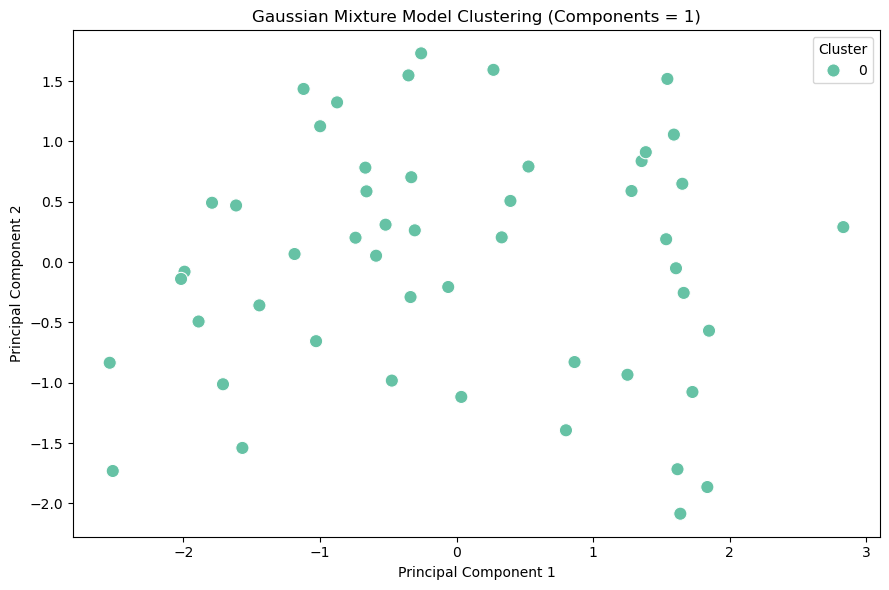

In [33]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=usarrests_clusters,
    x="PC1",
    y="PC2",
    hue="GMM_Cluster",
    palette="Set2",
    s=90
)

plt.title(
    f"Gaussian Mixture Model Clustering (Components = {optimal_gmm_clusters})"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()



### 6.14 Interpretation of GMM Clustering Results

The Gaussian Mixture Model was fitted using one component, as selected by the Bayesian Information Criterion (BIC).

All 50 states were assigned to Cluster 0.

The scatter plot confirms that the model treated all observations as belonging to a single Gaussian component rather than separating them into distinct groups.

This result indicates that, under the selected GMM settings, introducing additional Gaussian components was not sufficiently supported by the BIC criterion.

Although the observations appear spread across the PCA space, the model did not identify multiple clusters.

### 6.15 Comparison of K-Means and GMM Results

The two clustering methods produced different results.

| Criterion | K-Means | Gaussian Mixture Model |
|---|---|---|
| Cluster selection | Elbow method | Bayesian Information Criterion (BIC) |
| Selected clusters | 4 | 1 |
| Cluster sizes | 13, 10, 18, 9 | 50 |
| Assignment approach | Distance-based | Probability-based |
| Result | Four distinct groups | One overall group |

K-Means identified four groups of states based on their positions in the two-dimensional PCA space.

In contrast, GMM selected one component because additional components did not sufficiently improve the model fit after accounting for complexity.

The difference highlights how clustering outcomes depend on the underlying method and model selection criterion.

For identifying distinct groups of states in this analysis, K-Means provides a more detailed segmentation. The GMM result suggests that the evidence for multiple Gaussian components is insufficient under the tested settings.

Neither result independently establishes the true number of groups in the data.


In [34]:

# Add K-Means cluster labels to the original selected features
cluster_profiles = X_usarrests.copy()

cluster_profiles["Cluster"] = kmeans_labels

# Calculate the mean values for each cluster
cluster_summary = cluster_profiles.groupby("Cluster").mean()

print("Average Feature Values by K-Means Cluster:")
display(cluster_summary.round(2))


Average Feature Values by K-Means Cluster:


,Murder,Assault,UrbanPop
Cluster,,,
0,3.60,78.54,52.08
1,11.37,270.10,79.20
2,5.97,144.67,73.89
3,13.50,245.78,53.11



### 6.16 Interpretation of K-Means Cluster Characteristics

The average values of the selected features were examined to understand the characteristics of the four K-Means clusters.

**Cluster 0: Low Crime Arrest Rates and Lower Urbanization (13 States)**

- Average Murder: 3.60
- Average Assault: 78.54
- Average UrbanPop: 52.08%

This cluster recorded the lowest average murder and assault arrest rates, alongside the lowest urban population percentage. It represents states with relatively low violent crime arrest rates and lower urbanization.

**Cluster 1: High Crime Arrest Rates and High Urbanization (10 States)**

- Average Murder: 11.37
- Average Assault: 270.10
- Average UrbanPop: 79.20%

This cluster recorded the highest average assault arrest rate and urban population percentage. Its murder arrest rate was also relatively high, suggesting a group of highly urbanized states with elevated violent crime arrest rates.

**Cluster 2: Moderate Crime Arrest Rates and High Urbanization (18 States)**

- Average Murder: 5.97
- Average Assault: 144.67
- Average UrbanPop: 73.89%

This cluster recorded moderate murder and assault arrest rates, with a relatively high urban population percentage. It represents states with lower violent crime arrest rates than Clusters 1 and 3 despite relatively high urbanization.

**Cluster 3: High Murder Arrest Rates and Lower Urbanization (9 States)**

- Average Murder: 13.50
- Average Assault: 245.78
- Average UrbanPop: 53.11%

This cluster recorded the highest average murder arrest rate and the second-highest assault arrest rate. Its urban population percentage was relatively low, suggesting that high violent crime arrest rates are not confined to the most urbanized states.

### 6.17 Conclusion: USArrests Clustering Analysis

The analysis successfully selected three relevant features, standardized the data, and applied PCA to reduce the dataset to two principal components.

The two components explained **94.15% of the total variance**, retaining most of the information from the selected features.

The elbow method suggested four K-Means clusters, while BIC selected one Gaussian component for the GMM.

K-Means provided a more detailed grouping of states, revealing differences in violent crime arrest rates and urban population percentages.

The cluster profiles demonstrated that states with similar levels of urbanization do not necessarily have similar violent crime arrest rates.

Although GMM did not identify multiple clusters under the selected settings, its results provided a useful comparison with K-Means.

Overall, K-Means offered more interpretable groupings for exploring patterns in the USArrests dataset. These findings describe associations in the data and do not establish causal relationships between urbanization and crime.



## 7. Overall Project Conclusion

### 7.1 Summary of Findings

The DataVine Analytics project applied machine learning techniques to three datasets to address classification, recommendation, and clustering problems.

**Task 1: Wine Classification**

The Wine dataset was used to develop a k-Nearest Neighbors (k-NN) classification model.

After standardization, PCA retained 10 principal components explaining 96.24% of the variance.

GridSearchCV identified 11 neighbors and Euclidean distance as the best hyperparameters, achieving a cross-validation accuracy of 96.50%.

The final model achieved 100% accuracy on the 36 test observations, correctly classifying all three wine categories.

Although the results demonstrate strong performance on the test set, further testing on independent data would help establish how well the model generalizes.

**Task 2: Agricultural Feed Recommendation**

The Chickwts dataset was used to develop a feed recommendation system based on chicken weight outcomes.

PCA retained one principal component explaining 100% of the variance.

Cosine similarity grouped the six feed categories according to whether their average chicken weights were above or below the overall mean.

A supplementary comparison of average weights identified sunflower (328.92) and casein (323.58) as the closest-performing feeds.

The analysis demonstrated that cosine similarity has limited discriminatory power when each feed is represented by a single numerical value.

**Task 3: USArrests Clustering**

The USArrests dataset was used to identify groups of states with similar crime and demographic characteristics.

Three features were selected: Murder, Assault, and UrbanPop.

PCA reduced these features to two components explaining 94.15% of the total variance.

The elbow method suggested four K-Means clusters, revealing differences in violent crime arrest rates and urban population percentages.

In contrast, BIC selected one Gaussian component for the Gaussian Mixture Model.

The comparison demonstrated that different clustering approaches can produce different groupings of the same dataset.

### 7.2 Overall Conclusion

The project demonstrated the application of preprocessing, dimensionality reduction, supervised learning, similarity analysis, and unsupervised learning to different analytical problems.

PCA was useful for reducing the dimensionality of the Wine and USArrests datasets while retaining most of their variance.

The Wine classification model achieved strong predictive performance, while the feed recommendation analysis highlighted the limitations of cosine similarity when applied to one-dimensional data.

The clustering analysis demonstrated how K-Means and GMM can produce different results depending on their underlying assumptions and model selection criteria.

Overall, the project met its analytical objectives while highlighting the importance of selecting appropriate methods, interpreting results carefully, and acknowledging model limitations.
